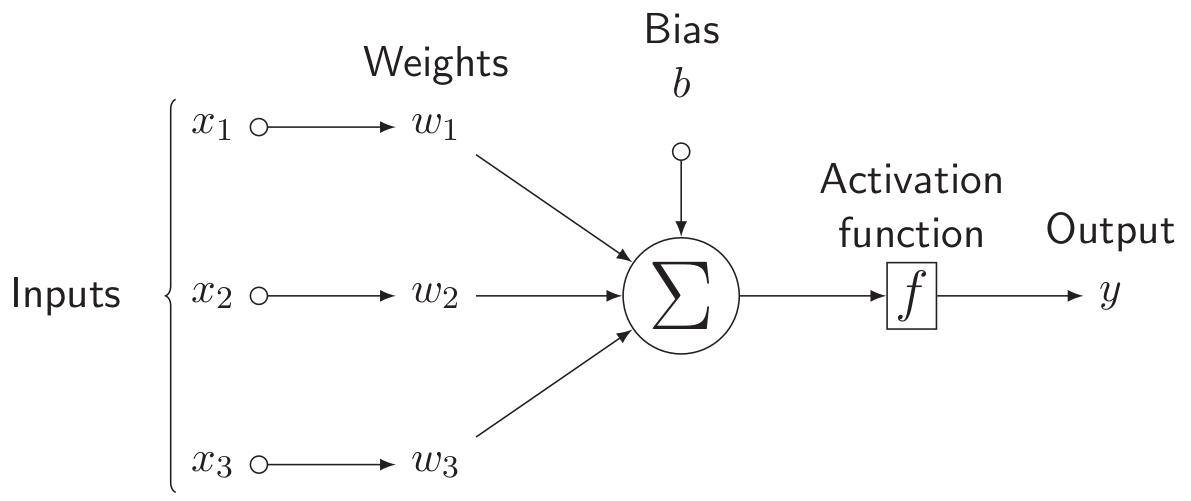

একটি Artificial Neuron-এর ৫টি প্রধান উপাদান:
1. Input
2. Weight
3. Bias
4. Weighted Sum
5. Activation Function



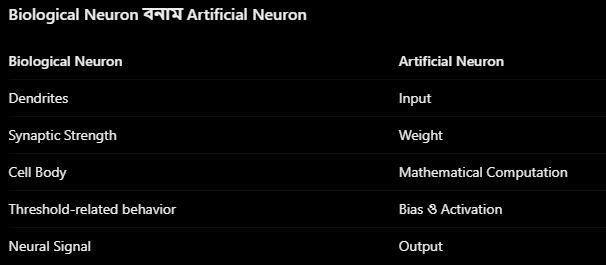

# Activation Function

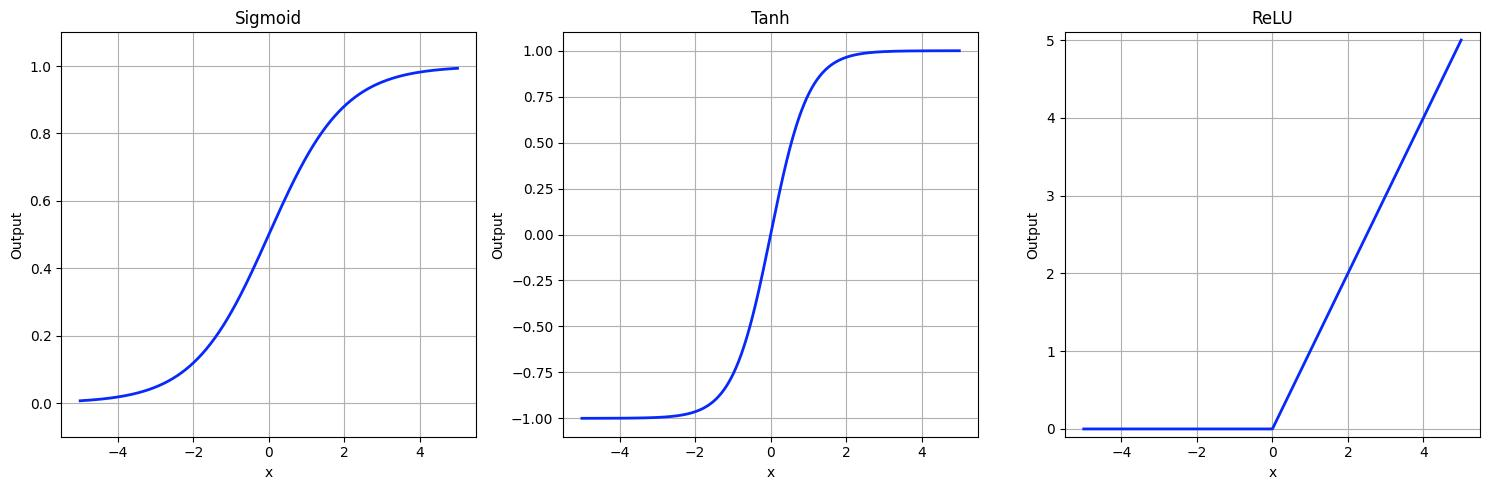

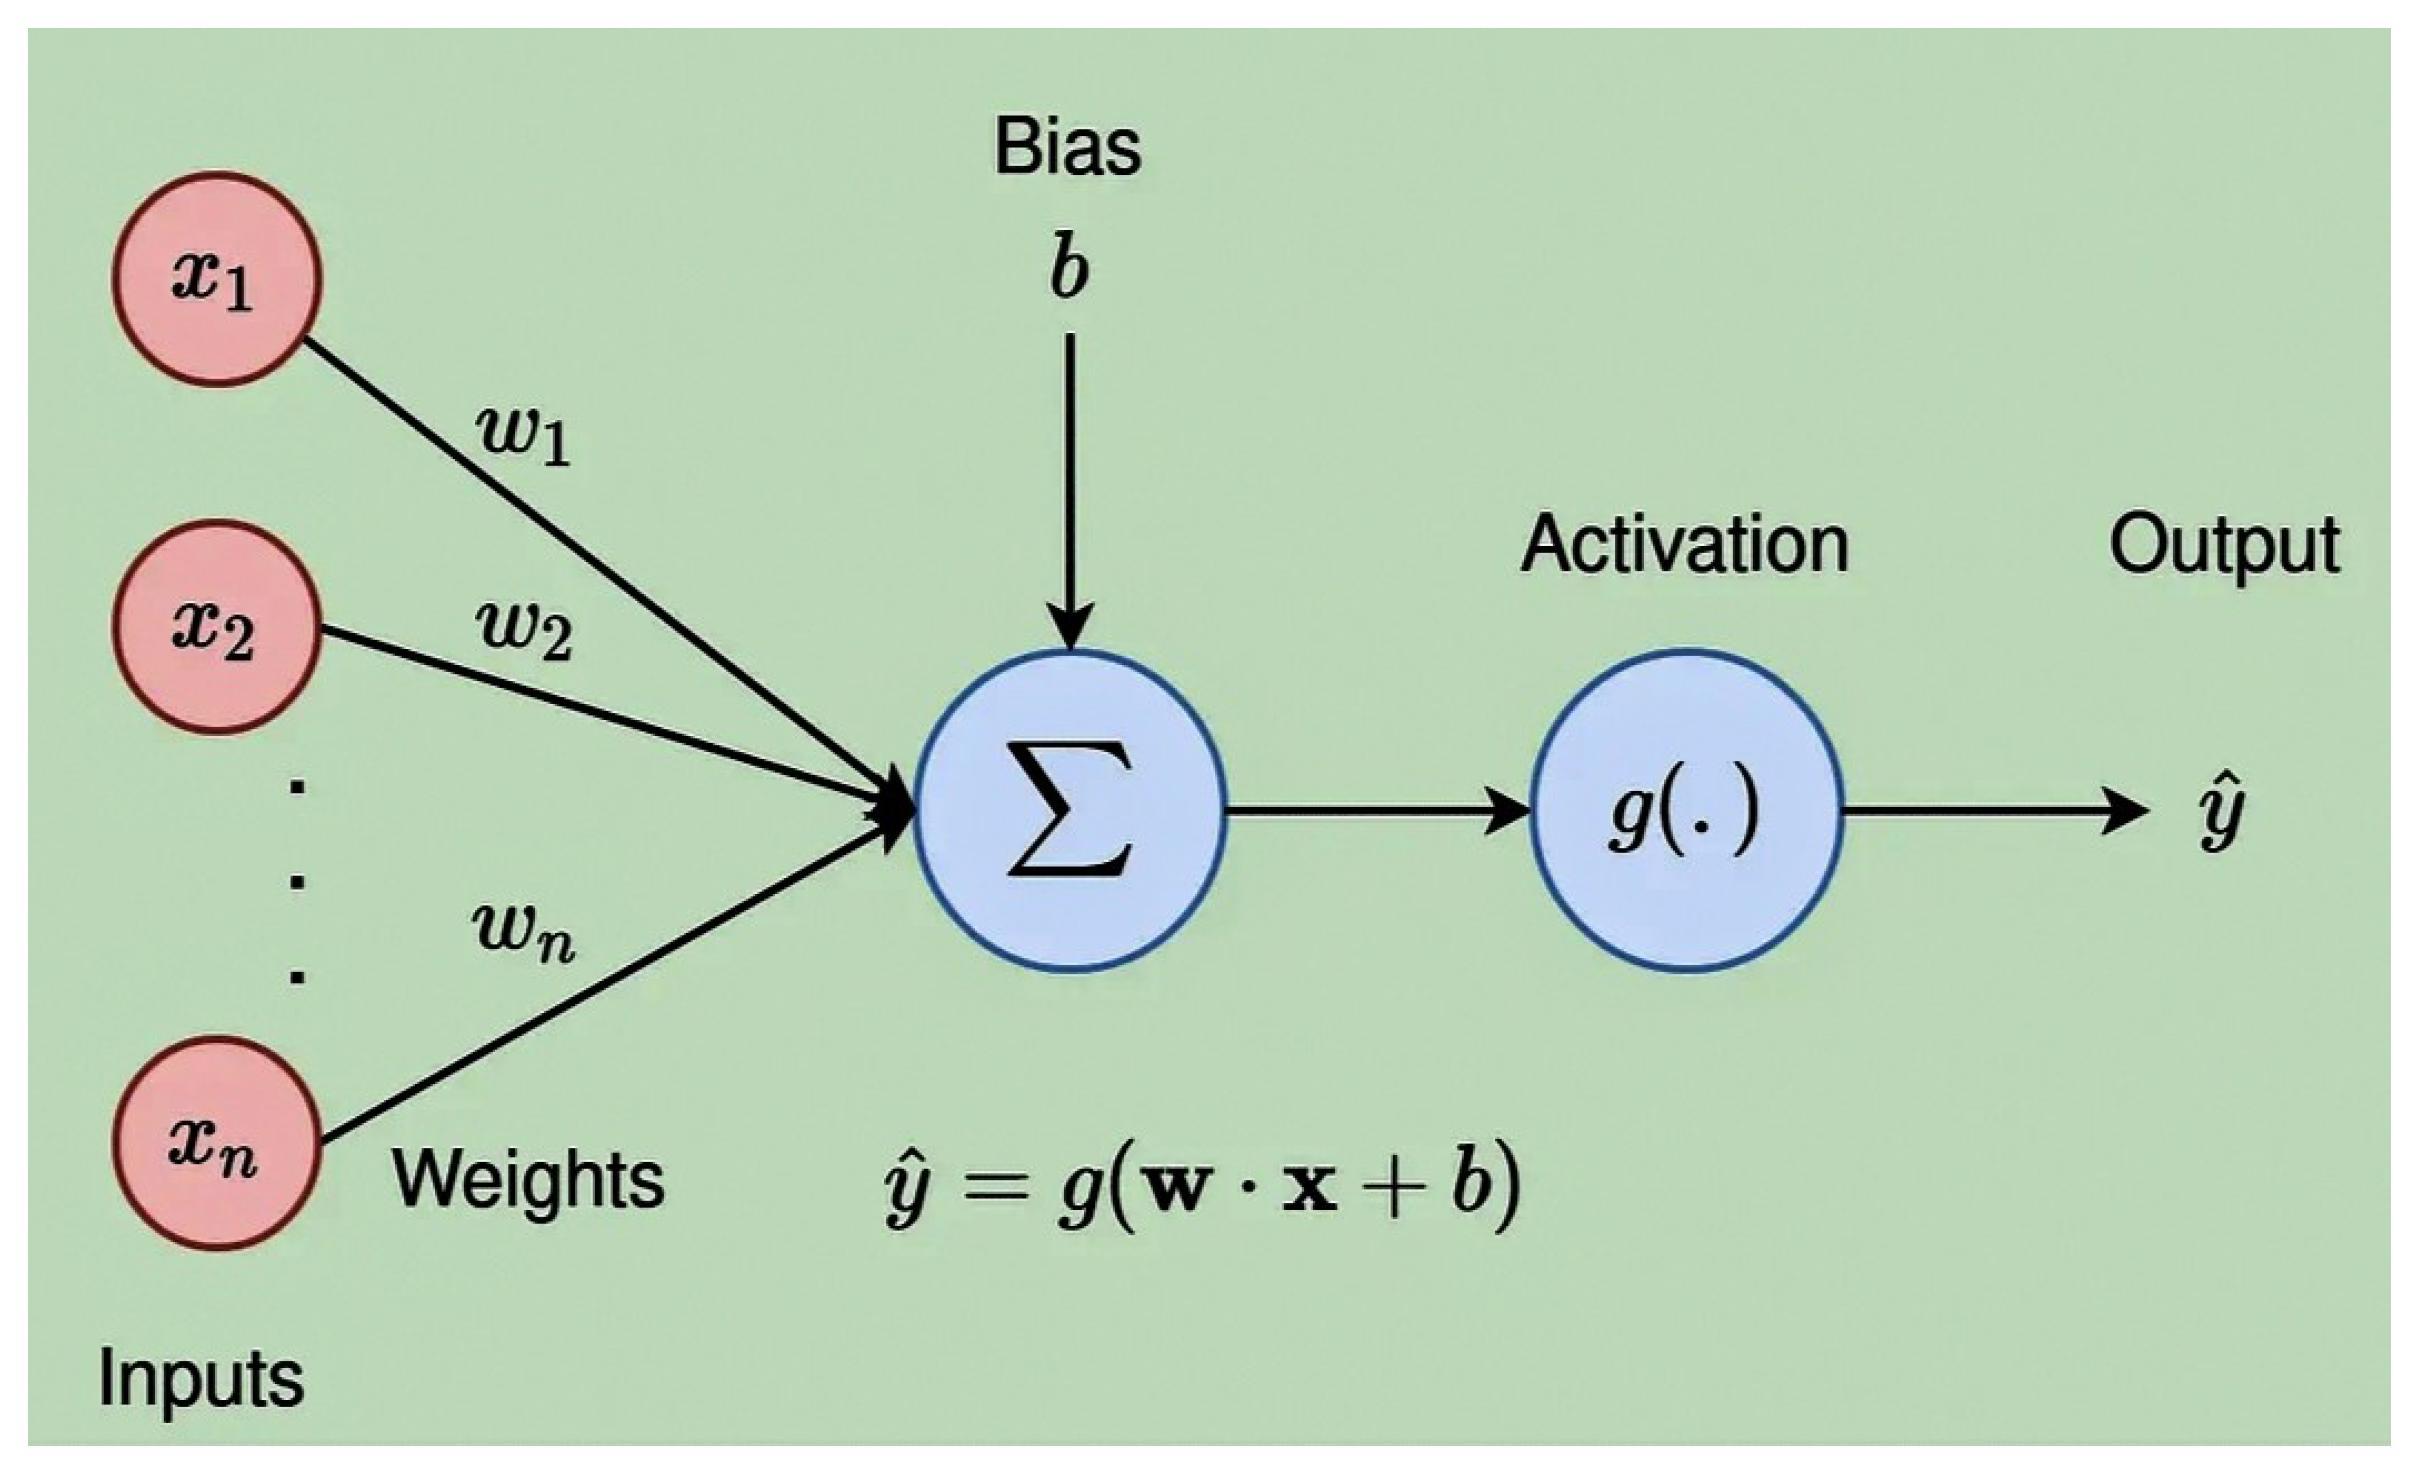

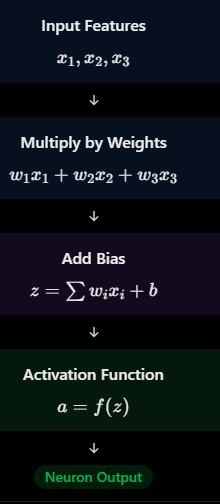

### Single Artificial Neuron(NumPy)

In [ ]:
import numpy as np

x=np.array([2.0, 3.0, 4.0])
w=np.array([0.5,0.25,0.75])
b=0.5

z=np.dot(x,w)+b #Weighted Sum

def sigmoid(z):
    return 1/(1+np.exp(-z))

a=sigmoid(z)
print(a)

0.9947798743064417


# Single Artificial Neuron(PyTorch)

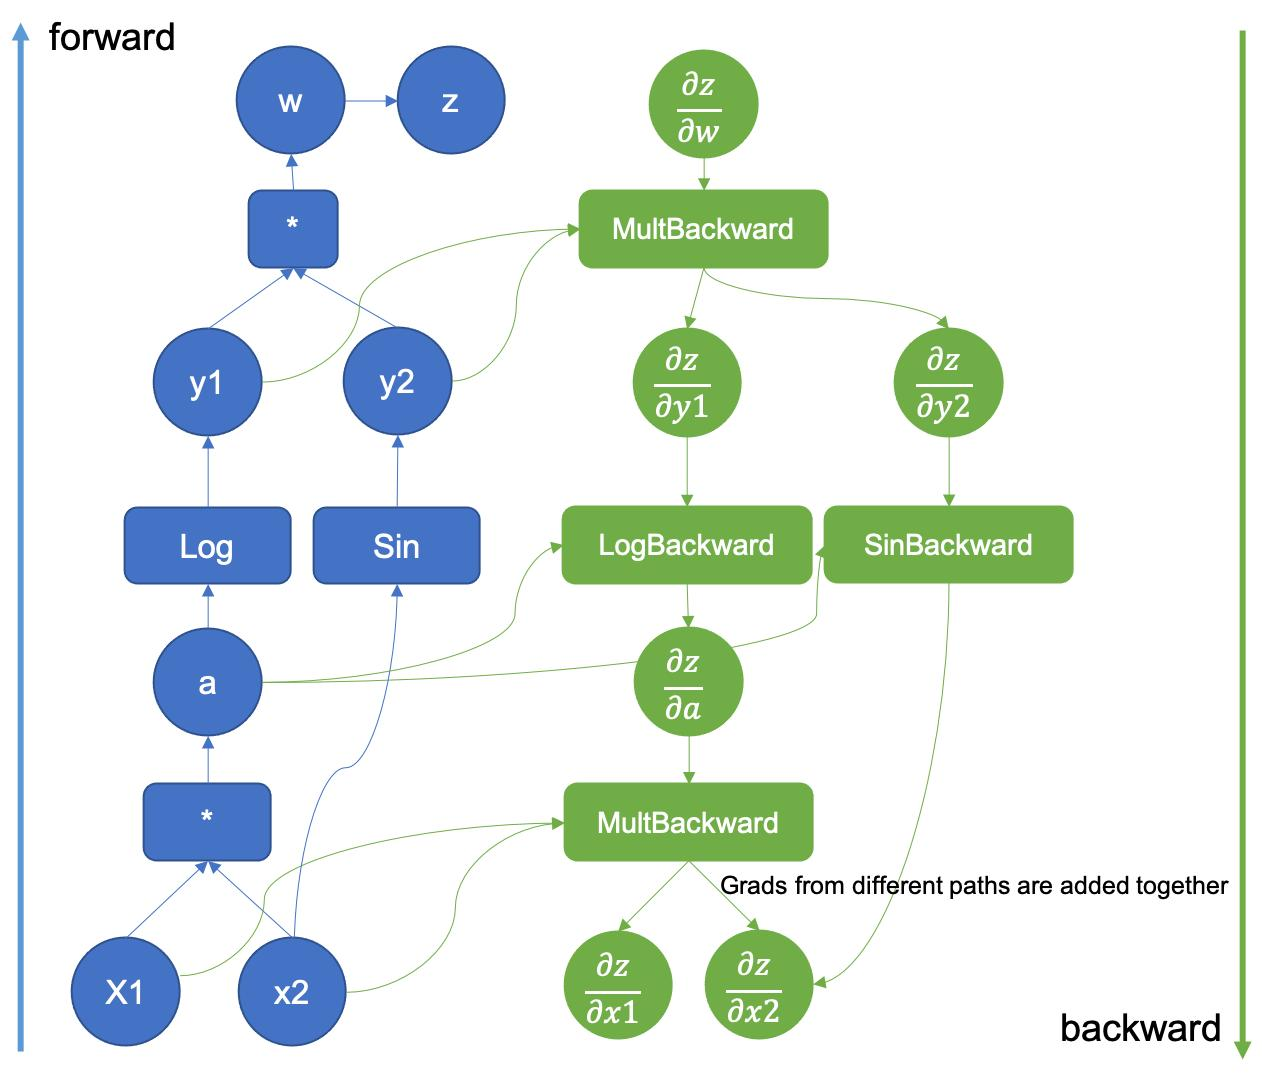

In [2]:
import torch
import torch.nn as nn

x = torch.tensor([[2.0, 3.0, 4.0]])
w = torch.tensor([[0.5],[0.25],[0.75]])
b = torch.tensor([0.5])

z=torch.matmul(x, w) + b  # Weighted Sum
a=torch.sigmoid(z)  # Apply Sigmoid Activation
print(a)

tensor([[0.9948]])


### nn.Module use

In [3]:
import torch
import torch.nn as nn


class SingleNeuron(nn.Module):

    def __init__(self):

        super().__init__()

        # 3 Input, 1 Output
        self.linear = nn.Linear(3, 1)

    def forward(self, x):

        z = self.linear(x)

        output = torch.sigmoid(z)

        return output


# Model তৈরি
model = SingleNeuron()

# Input
x = torch.tensor([[2.0, 3.0, 4.0]])

# Prediction
prediction = model(x)

print("Prediction:", prediction)

Prediction: tensor([[0.8861]], grad_fn=<SigmoidBackward0>)


# Perceptron

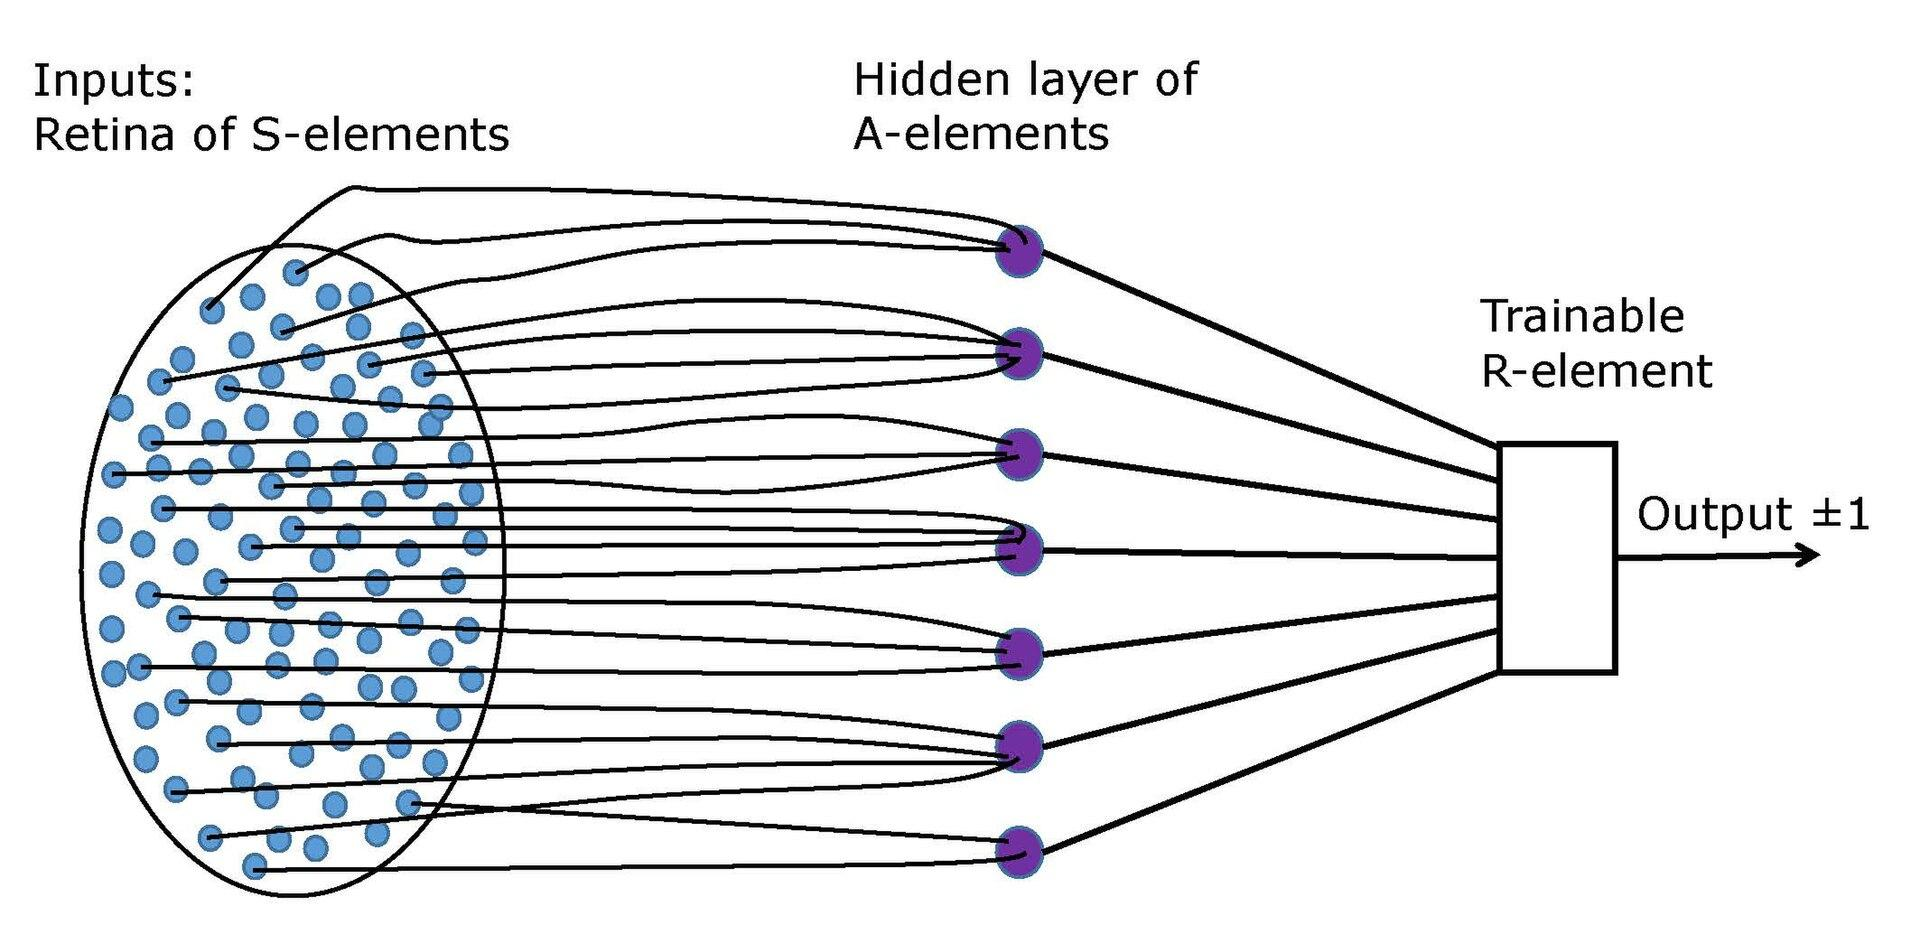


Perceptron-এর মূল কাজ:
1. Input গ্রহণ করা।
2. প্রতিটি Input-এর সঙ্গে Weight গুণ করা।
3. Bias যোগ করা।
4. Weighted Sum হিসাব করা।
5. Step Activation Function প্রয়োগ করা।
6. Prediction তৈরি করা।
7. Prediction ভুল হলে Weight ও Bias Update করা।

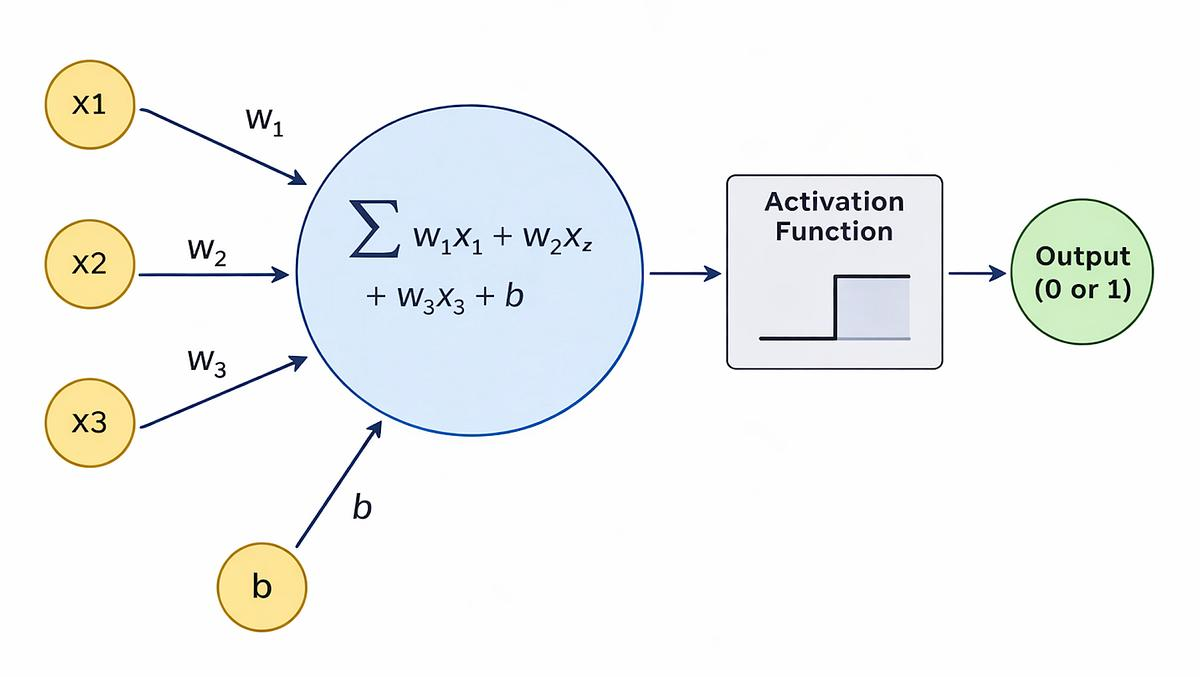

# Decision Boundary


Decision Boundary হলো এমন একটি সীমারেখা, যা বিভিন্ন Classes-কে আলাদা করে।

দুইটি Input Feature থাকলে:
\[
w_1x_1+w_2x_2+b=0
\]

এটাই Perceptron-এর Decision Boundary।

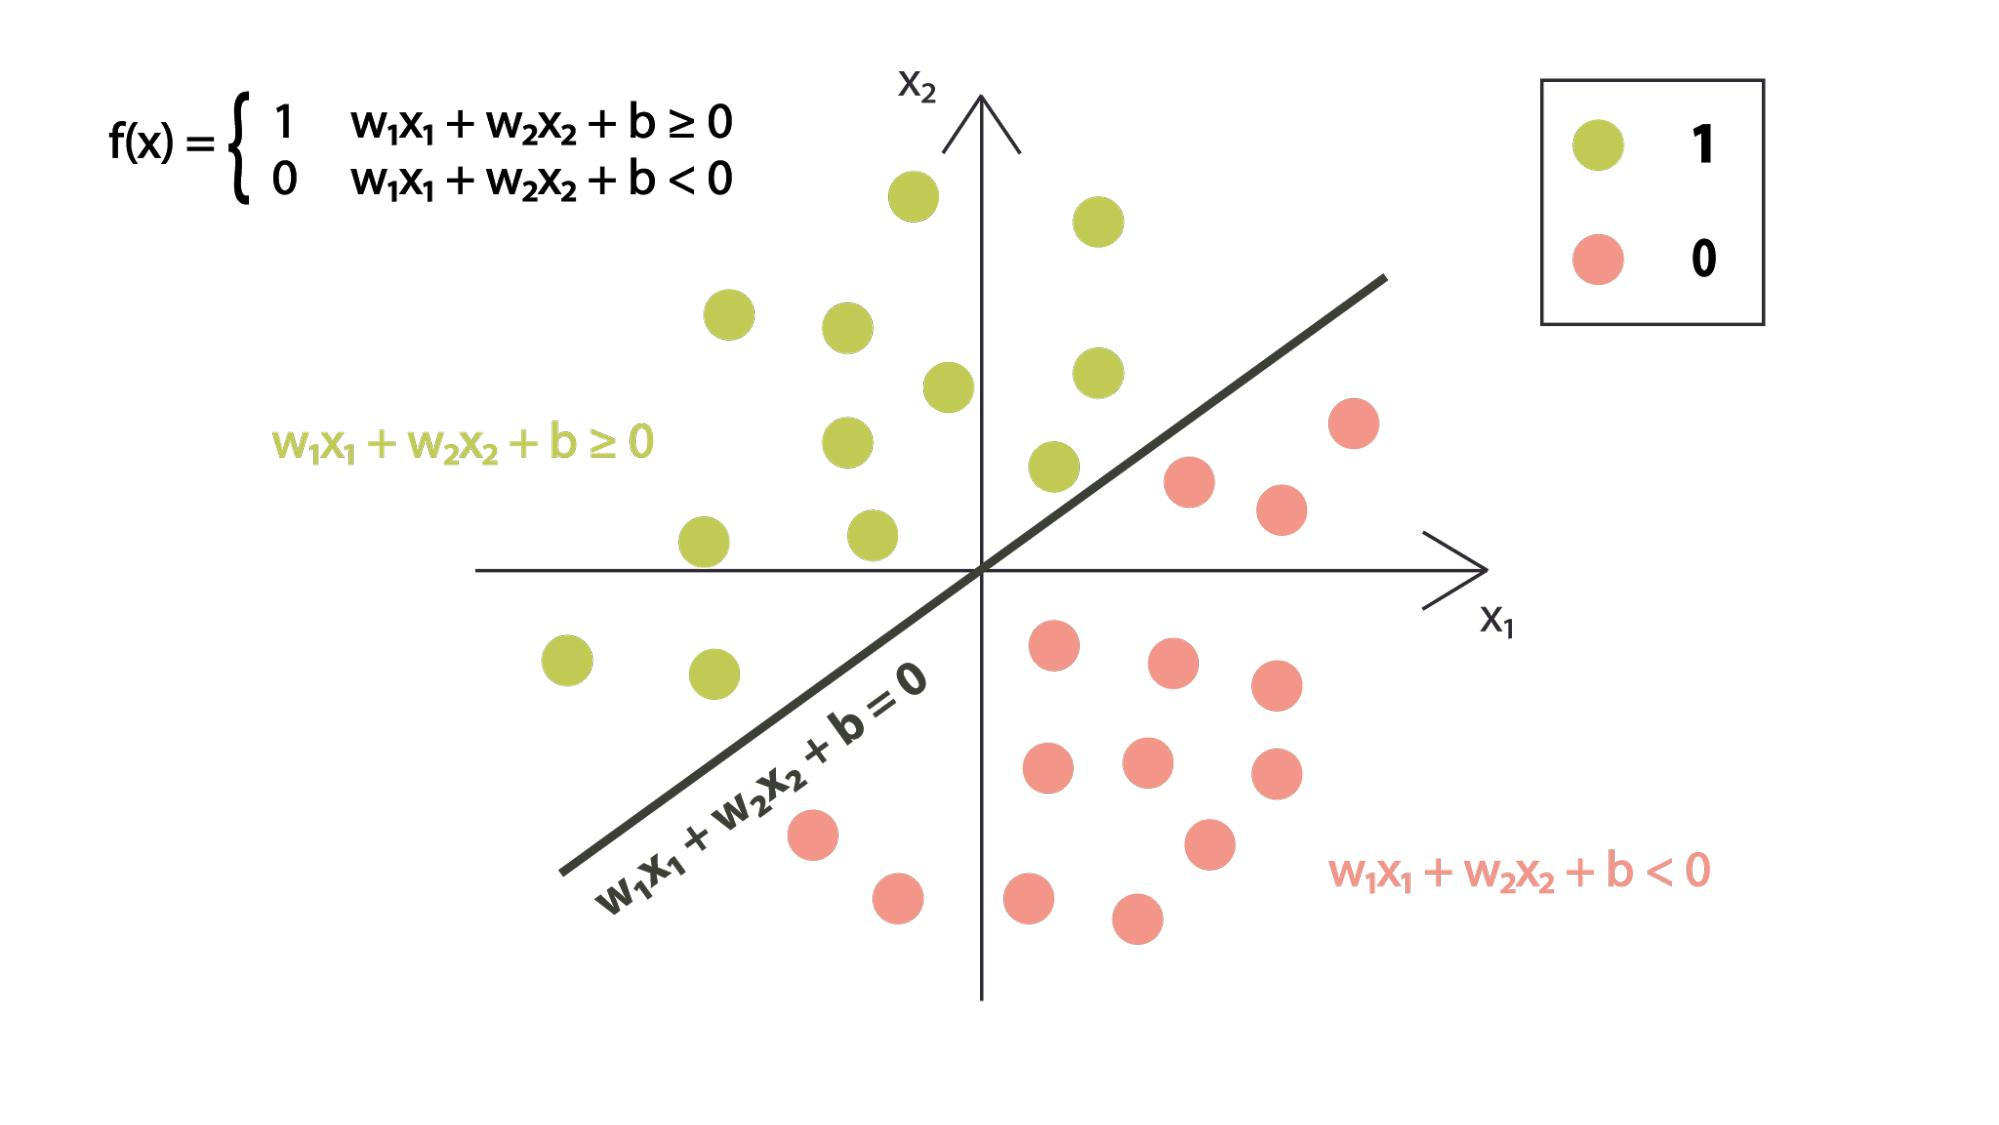

### Perceptron(PyTorch)

In [4]:
import torch

# Dataset
X = torch.tensor([
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0]
])

y = torch.tensor([0.0, 0.0, 0.0, 1.0])

# Parameters
weights = torch.zeros(2)
bias = torch.tensor(0.0)

learning_rate = 0.1

# Training
for epoch in range(20):

    errors = 0

    for i in range(len(X)):

        z = torch.dot(X[i], weights) + bias

        prediction = (z >= 0).float()

        error = y[i] - prediction

        weights += learning_rate * error * X[i]

        bias += learning_rate * error

        if error != 0:
            errors += 1

    print(f"Epoch {epoch + 1}: Errors = {errors}")

# Testing
print("\nFinal Parameters:")
print("Weights:", weights)
print("Bias:", bias)

print("\nPredictions:")

for i in range(len(X)):

    z = torch.dot(X[i], weights) + bias

    prediction = (z >= 0).float()

    print("Input:", X[i].tolist(),
          "Prediction:", prediction.item())

Epoch 1: Errors = 2
Epoch 2: Errors = 3
Epoch 3: Errors = 3
Epoch 4: Errors = 0
Epoch 5: Errors = 0
Epoch 6: Errors = 0
Epoch 7: Errors = 0
Epoch 8: Errors = 0
Epoch 9: Errors = 0
Epoch 10: Errors = 0
Epoch 11: Errors = 0
Epoch 12: Errors = 0
Epoch 13: Errors = 0
Epoch 14: Errors = 0
Epoch 15: Errors = 0
Epoch 16: Errors = 0
Epoch 17: Errors = 0
Epoch 18: Errors = 0
Epoch 19: Errors = 0
Epoch 20: Errors = 0

Final Parameters:
Weights: tensor([0.2000, 0.1000])
Bias: tensor(-0.2000)

Predictions:
Input: [0.0, 0.0] Prediction: 0.0
Input: [0.0, 1.0] Prediction: 0.0
Input: [1.0, 0.0] Prediction: 0.0
Input: [1.0, 1.0] Prediction: 1.0
